In [2]:
import pandas as pd

df = pd.read_csv("../data/monday.csv")

print(df.shape)

(371621, 89)


# CICIDS2017 Exploratory Data Analysis (EDA)

## Project: Network Anomaly Detection and Predictive Intrusion Monitoring Platform

### Objective
The objective of this analysis is to understand the CICIDS2017 network traffic dataset,
identify benign and malicious traffic, examine the distribution of attack categories,
check data quality, and identify useful network-flow features for subsequent anomaly
detection and intrusion monitoring.

### Dataset
CICIDS2017 contains labeled network-flow records representing normal traffic and
different types of attacks.

In [49]:
import pandas as pd

df = pd.read_csv("../data/monday.csv")

print(df.shape)

(371621, 89)


In [50]:
df.head()

,Src IP dec,Src Port,Dst IP dec,Dst Port,Protocol,Timestamp,Flow Duration,Total Fwd Packet,Total Bwd packets,Total Length of Fwd Packet,...,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,ICMP Code,ICMP Type,Total TCP Flow Time,Label,Attempted Category
0,134610945,0,134219268,0,0,56:34.2,119719148,231,0,0,...,17,12685486.0,5.296658e+06,20694308,6499982,-1,-1,0,BENIGN,-1
1,3232238089,123,3232238083,123,17,56:55.4,65511209,6,6,288,...,1506210,64004884.0,0.000000e+00,64004884,64004884,-1,-1,0,BENIGN,-1
2,3232238092,5353,3758096635,5353,17,57:21.1,113976922,267,0,20447,...,14,25498178.0,1.883305e+07,48523116,5463561,-1,-1,0,BENIGN,-1
3,3232238092,123,2550302004,123,17,57:31.6,67037196,8,8,384,...,11034681,55956316.0,0.000000e+00,55956316,55956316,-1,-1,0,BENIGN,-1
4,3232238092,123,760155097,123,17,57:30.6,68045057,8,8,384,...,11043596,56943904.0,0.000000e+00,56943904,56943904,-1,-1,0,BENIGN,-1


In [51]:
print(df.columns.tolist())

['Src IP dec', 'Src Port', 'Dst IP dec', 'Dst Port', 'Protocol', 'Timestamp', 'Flow Duration', 'Total Fwd Packet', 'Total Bwd packets', 'Total Length of Fwd Packet', 'Total Length of Bwd Packet', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd RST Flags', 'Bwd RST Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH

In [52]:
import pandas as pd
import matplotlib.pyplot as plt

## 1. Dataset Overview

In [55]:
print("Number of columns:", len(df_wednesday.columns))
print("\nColumn names:")
print(df_wednesday.columns.tolist())

Number of columns: 90

Column names:
['Src IP dec', 'Src Port', 'Dst IP dec', 'Dst Port', 'Protocol', 'Timestamp', 'Flow Duration', 'Total Fwd Packet', 'Total Bwd packets', 'Total Length of Fwd Packet', 'Total Length of Bwd Packet', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd RST Flags', 'Bwd RST Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SY

In [56]:
print(df_wednesday.dtypes)

Src IP dec              int64
Src Port                int64
Dst IP dec              int64
Dst Port                int64
Protocol                int64
                        ...  
ICMP Type               int64
Total TCP Flow Time     int64
Label                  object
Attempted Category      int64
Traffic_Type           object
Length: 90, dtype: object


## 3. Data Quality

In [58]:
print("Missing values:", df_wednesday.isnull().sum().sum())

Missing values: 0


In [59]:
print("Duplicate rows:", df_wednesday.duplicated().sum())

Duplicate rows: 6


## 4. Traffic Label Distribution

In [62]:
print(df_wednesday["Label"].value_counts())

Label
BENIGN                          319119
DoS Hulk                        158468
DoS GoldenEye                     7567
DoS Slowloris                     3859
DoS Slowhttptest - Attempted      3368
DoS Slowloris - Attempted         1847
DoS Slowhttptest                  1740
DoS Hulk - Attempted               581
DoS GoldenEye - Attempted           80
Heartbleed                          11
Name: count, dtype: int64


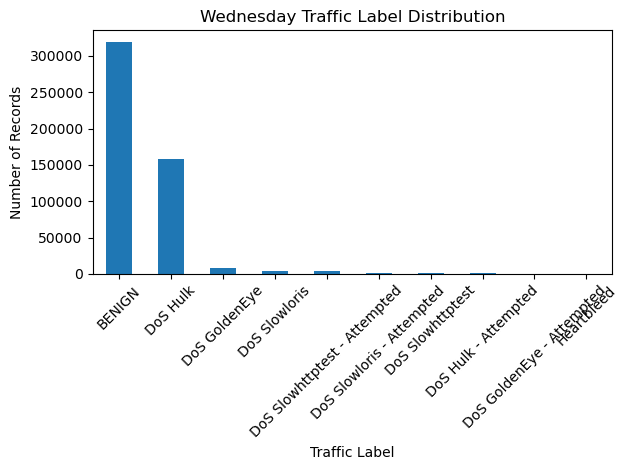

In [63]:
df_wednesday["Label"].value_counts().plot(kind="bar")

plt.title("Wednesday Traffic Label Distribution")
plt.xlabel("Traffic Label")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [64]:
label_percentage = (
    df_wednesday["Label"]
    .value_counts(normalize=True) * 100
)

print(label_percentage)

Label
BENIGN                          64.255598
DoS Hulk                        31.908022
DoS GoldenEye                    1.523639
DoS Slowloris                    0.777022
DoS Slowhttptest - Attempted     0.678157
DoS Slowloris - Attempted        0.371899
DoS Slowhttptest                 0.350354
DoS Hulk - Attempted             0.116986
DoS GoldenEye - Attempted        0.016108
Heartbleed                       0.002215
Name: proportion, dtype: float64


## 5. Benign vs Attack Traffic

In [66]:
traffic_type = df_wednesday["Label"].apply(
    lambda x: "BENIGN" if x == "BENIGN" else "ATTACK"
)

print(traffic_type.value_counts())

Label
BENIGN    319119
ATTACK    177521
Name: count, dtype: int64


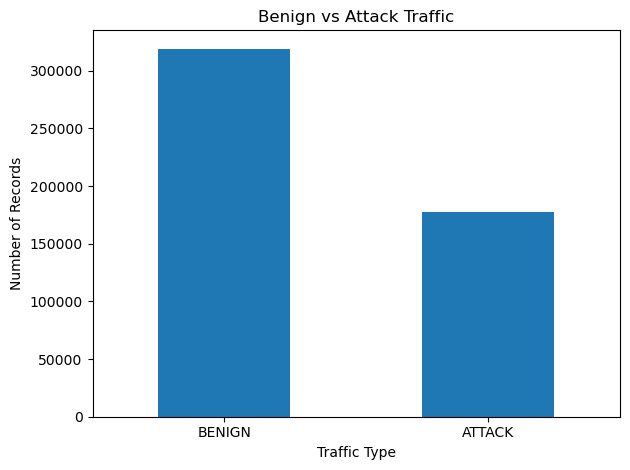

In [67]:
traffic_type.value_counts().plot(kind="bar")

plt.title("Benign vs Attack Traffic")
plt.xlabel("Traffic Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 6. Numerical Feature Analysis

In [69]:
numeric_columns = df_wednesday.select_dtypes(
    include="number"
).columns

print("Number of numerical columns:", len(numeric_columns))
print(numeric_columns.tolist())

Number of numerical columns: 87
['Src IP dec', 'Src Port', 'Dst IP dec', 'Dst Port', 'Protocol', 'Flow Duration', 'Total Fwd Packet', 'Total Bwd packets', 'Total Length of Fwd Packet', 'Total Length of Bwd Packet', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd RST Flags', 'Bwd RST Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RS

In [1]:
df_wednesday[numeric_columns].describe()

NameError: name 'df_wednesday' is not defined

In [71]:
print(df_wednesday["Flow Duration"].describe())

count    4.966400e+05
mean     1.210240e+07
std      3.078214e+07
min      1.000000e+00
25%      3.048100e+04
50%      1.559870e+05
75%      1.271786e+06
max      1.200000e+08
Name: Flow Duration, dtype: float64


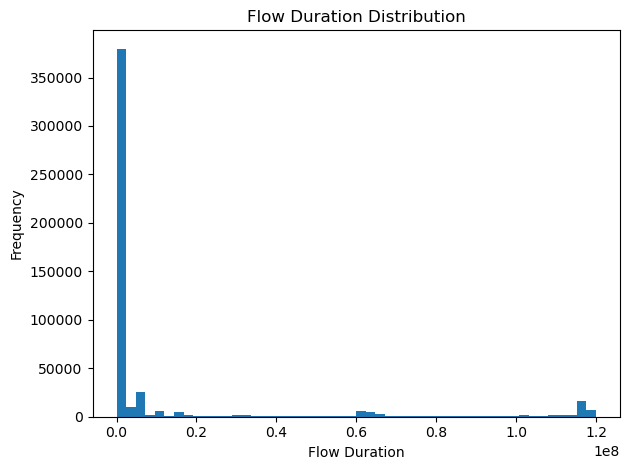

In [72]:
df_wednesday["Flow Duration"].plot(
    kind="hist",
    bins=50
)

plt.title("Flow Duration Distribution")
plt.xlabel("Flow Duration")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

In [73]:
features = [
    "Total Fwd Packet",
    "Total Bwd packets"
]

print(df_wednesday[features].describe())

       Total Fwd Packet  Total Bwd packets
count     496640.000000      496640.000000
mean          13.214097          14.454698
std          882.426050        1162.333891
min            0.000000           0.000000
25%            2.000000           2.000000
50%            6.000000           5.000000
75%            9.000000           7.000000
max       203943.000000      272354.000000


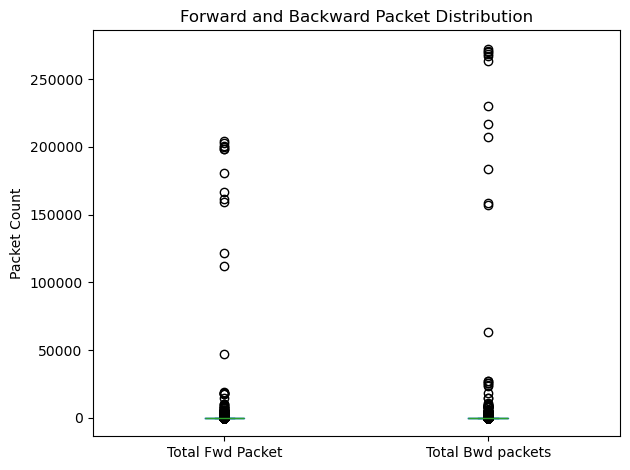

In [74]:
df_wednesday[features].plot(
    kind="box"
)

plt.title("Forward and Backward Packet Distribution")
plt.ylabel("Packet Count")
plt.tight_layout()
plt.show()

## EDA Observations

- The dataset contains both normal and malicious network traffic.
- The `Label` column identifies the traffic category.
- Different attack categories are present across the network traffic datasets.
- The dataset contains multiple numerical network-flow features.
- Class imbalance is present, with some traffic categories having more records than others.

In [118]:
print("Number of records:", len(df))
print("Number of columns:", len(df.columns))
print("Duplicate rows:", df.duplicated().sum())

Number of records: 371621
Number of columns: 89
Duplicate rows: 4


In [119]:
df_monday = pd.read_csv("../data/monday.csv")
df_tuesday = pd.read_csv("../data/tuesday.csv")
df_wednesday = pd.read_csv("../data/wednesday.csv")
df_thursday = pd.read_csv("../data/thursday.csv")
df_friday = pd.read_csv("../data/friday.csv")

print("Monday:", df_monday.shape)
print("Tuesday:", df_tuesday.shape)
print("Wednesday:", df_wednesday.shape)
print("Thursday:", df_thursday.shape)
print("Friday:", df_friday.shape)

Monday: (371621, 89)
Tuesday: (322078, 89)
Wednesday: (496640, 89)
Thursday: (362075, 89)
Friday: (547557, 89)


## Traffic Label Distribution

The `Label` column is analyzed to understand the distribution of
benign and attack traffic across the different days.

In [121]:
print("MONDAY")
print(df_monday["Label"].value_counts())

print("\nTUESDAY")
print(df_tuesday["Label"].value_counts())

print("\nWEDNESDAY")
print(df_wednesday["Label"].value_counts())

print("\nTHURSDAY")
print(df_thursday["Label"].value_counts())

print("\nFRIDAY")
print(df_friday["Label"].value_counts())

MONDAY
Label
BENIGN    371621
Name: count, dtype: int64

TUESDAY
Label
BENIGN                     315106
FTP-Patator                  3972
SSH-Patator                  2961
SSH-Patator - Attempted        27
FTP-Patator - Attempted        12
Name: count, dtype: int64

WEDNESDAY
Label
BENIGN                          319119
DoS Hulk                        158468
DoS GoldenEye                     7567
DoS Slowloris                     3859
DoS Slowhttptest - Attempted      3368
DoS Slowloris - Attempted         1847
DoS Slowhttptest                  1740
DoS Hulk - Attempted               581
DoS GoldenEye - Attempted           80
Heartbleed                          11
Name: count, dtype: int64

THURSDAY
Label
BENIGN                                    288171
Infiltration - Portscan                    71767
Web Attack - Brute Force - Attempted        1292
Web Attack - XSS - Attempted                 655
Web Attack - Brute Force                      73
Infiltration - Attempted               

## Wednesday Traffic Distribution

Wednesday contains benign traffic and several attack categories.
The following visualization shows the distribution of traffic labels.

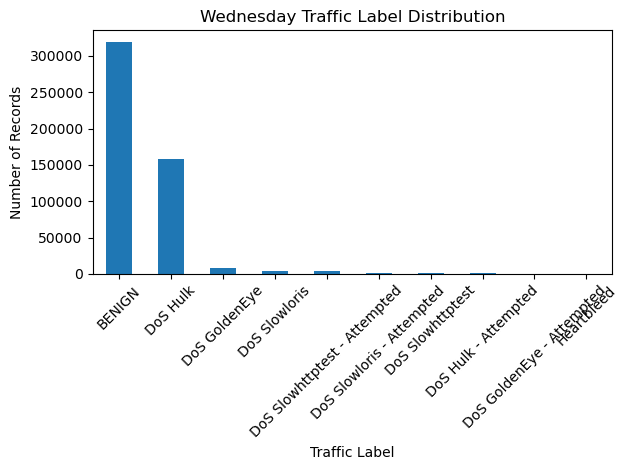

In [122]:
df_wednesday["Label"].value_counts().plot(kind="bar")

plt.title("Wednesday Traffic Label Distribution")
plt.xlabel("Traffic Label")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [123]:
traffic_type = df_wednesday["Label"].apply(
    lambda x: "BENIGN" if x == "BENIGN" else "ATTACK"
)

print(traffic_type.value_counts())

Label
BENIGN    319119
ATTACK    177521
Name: count, dtype: int64


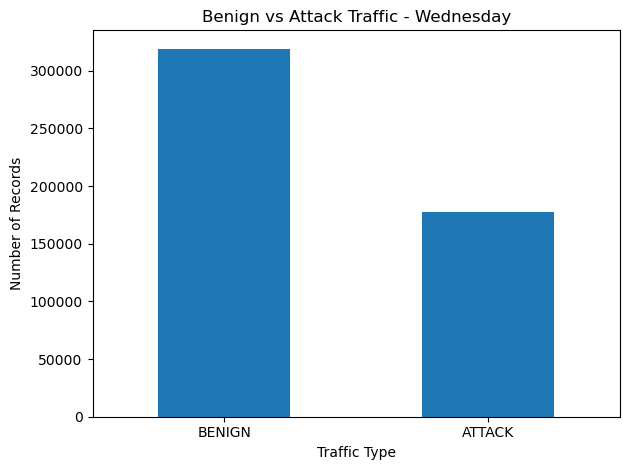

In [124]:
traffic_type.value_counts().plot(kind="bar")

plt.title("Benign vs Attack Traffic - Wednesday")
plt.xlabel("Traffic Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [125]:
df_thursday = pd.read_csv("../data/thursday.csv")

print("Thursday Shape:", df_thursday.shape)
print("\nThursday Labels:")
print(df_thursday["Label"].value_counts())

Thursday Shape: (362075, 89)

Thursday Labels:
Label
BENIGN                                    288171
Infiltration - Portscan                    71767
Web Attack - Brute Force - Attempted        1292
Web Attack - XSS - Attempted                 655
Web Attack - Brute Force                      73
Infiltration - Attempted                      45
Infiltration                                  36
Web Attack - XSS                              18
Web Attack - SQL Injection                    13
Web Attack - SQL Injection - Attempted         5
Name: count, dtype: int64


In [126]:
df_friday = pd.read_csv("../data/friday.csv")

print("Friday Shape:", df_friday.shape)
print("\nFriday Labels:")
print(df_friday["Label"].value_counts())

Friday Shape: (547557, 89)

Friday Labels:
Label
BENIGN                288544
Portscan              159066
DDoS                   95144
Botnet - Attempted      4067
Botnet                   736
Name: count, dtype: int64


In [127]:
df_friday = pd.read_csv("../data/friday.csv")

print("Friday Shape:", df_friday.shape)

print("\nFriday Labels:")
print(df_friday["Label"].value_counts())

Friday Shape: (547557, 89)

Friday Labels:
Label
BENIGN                288544
Portscan              159066
DDoS                   95144
Botnet - Attempted      4067
Botnet                   736
Name: count, dtype: int64


## Traffic Label Distribution

The traffic labels were examined across the CICIDS2017 datasets to identify
benign traffic and different categories of network attacks.

The datasets contain both normal (`BENIGN`) traffic and multiple attack
categories. The distribution of records varies considerably between
different traffic labels, indicating class imbalance in the dataset.

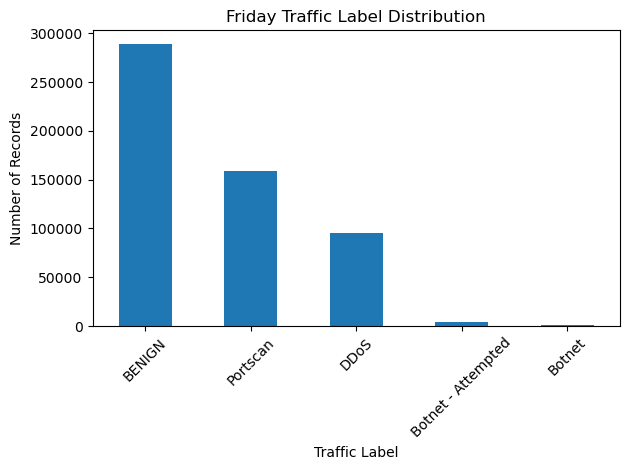

In [128]:
df_friday["Label"].value_counts().plot(kind="bar")

plt.title("Friday Traffic Label Distribution")
plt.xlabel("Traffic Label")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Benign vs Attack Traffic

To simplify the analysis, the traffic labels are grouped into two categories:

- **BENIGN** – normal network traffic
- **ATTACK** – all other traffic labels representing attack-related activity

This grouping helps us understand the overall proportion of normal and malicious traffic in the dataset.

In [130]:
def classify_traffic(label):
    if label == "BENIGN":
        return "BENIGN"
    else:
        return "ATTACK"


monday_type = df_monday["Label"].apply(classify_traffic)
tuesday_type = df_tuesday["Label"].apply(classify_traffic)
wednesday_type = df_wednesday["Label"].apply(classify_traffic)
thursday_type = df_thursday["Label"].apply(classify_traffic)
friday_type = df_friday["Label"].apply(classify_traffic)

print("Monday:")
print(monday_type.value_counts())

print("\nTuesday:")
print(tuesday_type.value_counts())

print("\nWednesday:")
print(wednesday_type.value_counts())

print("\nThursday:")
print(thursday_type.value_counts())

print("\nFriday:")
print(friday_type.value_counts())

Monday:
Label
BENIGN    371621
Name: count, dtype: int64

Tuesday:
Label
BENIGN    315106
ATTACK      6972
Name: count, dtype: int64

Wednesday:
Label
BENIGN    319119
ATTACK    177521
Name: count, dtype: int64

Thursday:
Label
BENIGN    288171
ATTACK     73904
Name: count, dtype: int64

Friday:
Label
BENIGN    288544
ATTACK    259013
Name: count, dtype: int64


In [120]:
print("Monday Shape:", df.shape)
print("Tuesday Shape:", df_tuesday.shape)
print("Wednesday Shape:", df_wednesday.shape)
print("Thursday Shape:", df_thursday.shape)
print("Friday Shape:", df_friday.shape)

Monday Shape: (371621, 89)
Tuesday Shape: (322078, 89)
Wednesday Shape: (496640, 89)
Thursday Shape: (362075, 89)
Friday Shape: (547557, 89)


## Benign vs Attack Traffic - Wednesday

The following visualization compares normal and attack-related traffic in the Wednesday dataset.

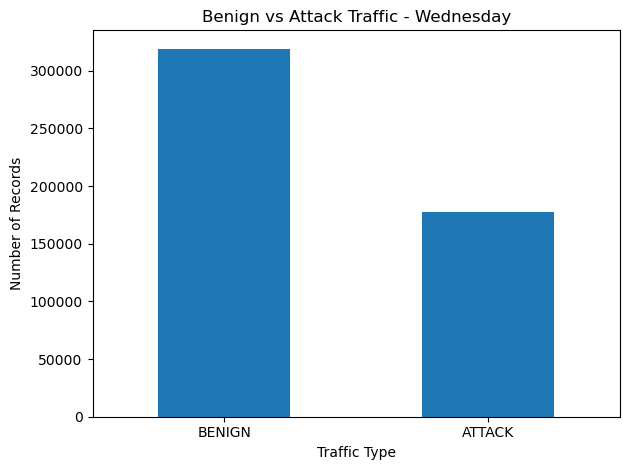

In [131]:
wednesday_type.value_counts().plot(kind="bar")

plt.title("Benign vs Attack Traffic - Wednesday")
plt.xlabel("Traffic Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Numerical Feature Analysis

Numerical network-flow features provide information about the behavior of network connections.

In this section, numerical features are examined using descriptive statistics and visualizations.
Features such as flow duration and packet counts can help identify differences in network traffic behavior.

In [132]:
numeric_columns = df_wednesday.select_dtypes(include="number").columns

print("Number of numerical columns:", len(numeric_columns))
print("\nNumerical columns:")
print(numeric_columns.tolist())

Number of numerical columns: 87

Numerical columns:
['Src IP dec', 'Src Port', 'Dst IP dec', 'Dst Port', 'Protocol', 'Flow Duration', 'Total Fwd Packet', 'Total Bwd packets', 'Total Length of Fwd Packet', 'Total Length of Bwd Packet', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd RST Flags', 'Bwd RST Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', '

In [133]:
df_wednesday[numeric_columns].describe()

,Src IP dec,Src Port,Dst IP dec,Dst Port,Protocol,Flow Duration,Total Fwd Packet,Total Bwd packets,Total Length of Fwd Packet,Total Length of Bwd Packet,...,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,ICMP Code,ICMP Type,Total TCP Flow Time,Attempted Category
count,4.966400e+05,496640.000000,4.966400e+05,496640.000000,496640.000000,4.966400e+05,496640.000000,496640.000000,496640.000000,4.966400e+05,...,4.966400e+05,4.966400e+05,4.966400e+05,4.966400e+05,4.966400e+05,4.966400e+05,496640.000000,496640.000000,4.966400e+05,496640.000000
mean,3.107179e+09,48202.464469,2.939000e+09,210.367729,10.488809,1.210240e+07,13.214097,14.454698,622.437661,2.381205e+04,...,2.579237e+05,1.018513e+05,4.340820e+06,4.725100e+05,4.805795e+06,3.927907e+06,-0.999847,-0.999742,4.410486e+07,-0.952859
std,1.784051e+08,13889.100033,7.397861e+08,1903.128172,5.412645,3.078214e+07,882.426050,1162.333891,4791.597323,2.646553e+06,...,1.361891e+06,7.916558e+05,1.428775e+07,3.568532e+06,1.539774e+07,1.393295e+07,0.028872,0.040732,4.203993e+08,0.539057
min,1.346109e+08,0.000000,1.885313e+07,0.000000,0.000000,1.000000e+00,0.000000,0.000000,0.000000,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000,-1.000000,0.000000e+00,-1.000000
25%,2.886730e+09,41236.000000,3.232238e+09,53.000000,6.000000,3.048100e+04,2.000000,2.000000,70.000000,1.580000e+02,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000,-1.000000,0.000000e+00,-1.000000
50%,3.232238e+09,52096.000000,3.232238e+09,80.000000,6.000000,1.559870e+05,6.000000,5.000000,308.000000,8.590000e+02,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000,-1.000000,9.804650e+04,-1.000000
75%,3.232238e+09,58614.000000,3.232238e+09,80.000000,17.000000,1.271786e+06,9.000000,7.000000,377.000000,1.159500e+04,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000,-1.000000,1.197753e+06,-1.000000
max,3.559744e+09,65535.000000,4.294967e+09,65178.000000,17.000000,1.200000e+08,203943.000000,272354.000000,819734.000000,6.270464e+08,...,1.049884e+08,1.002421e+08,1.199463e+08,7.691483e+07,1.199463e+08,1.199463e+08,10.000000,8.000000,3.029044e+10,6.000000


### Flow Duration Analysis

Flow Duration represents the duration of a network flow.

Analyzing this feature helps us understand how long network connections remain active and how traffic behavior varies across network flows.

In [134]:
print(df_wednesday["Flow Duration"].describe())

count    4.966400e+05
mean     1.210240e+07
std      3.078214e+07
min      1.000000e+00
25%      3.048100e+04
50%      1.559870e+05
75%      1.271786e+06
max      1.200000e+08
Name: Flow Duration, dtype: float64


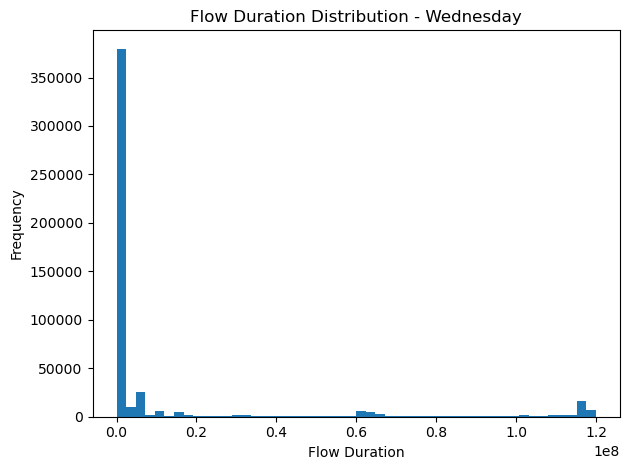

In [135]:
df_wednesday["Flow Duration"].plot(kind="hist", bins=50)

plt.title("Flow Duration Distribution - Wednesday")
plt.xlabel("Flow Duration")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

### Packet Count Analysis

Forward and backward packet counts describe the amount of traffic exchanged in the two directions of a network flow.

These features can help identify differences in normal and attack-related network traffic.

In [136]:
packet_features = ["Total Fwd Packet", "Total Bwd packets"]

print(df_wednesday[packet_features].describe())

       Total Fwd Packet  Total Bwd packets
count     496640.000000      496640.000000
mean          13.214097          14.454698
std          882.426050        1162.333891
min            0.000000           0.000000
25%            2.000000           2.000000
50%            6.000000           5.000000
75%            9.000000           7.000000
max       203943.000000      272354.000000


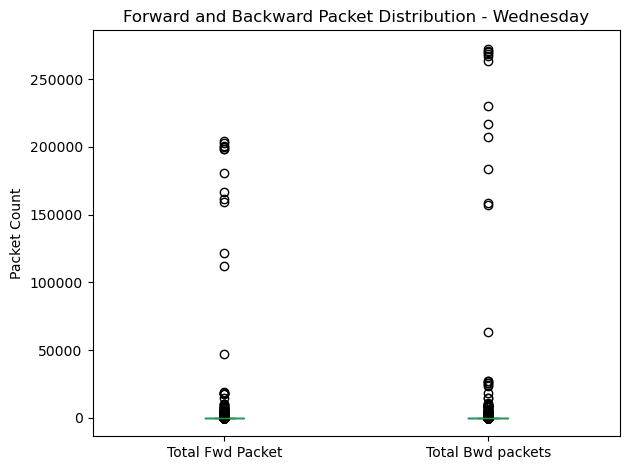

In [137]:
df_wednesday[packet_features].plot(kind="box")

plt.title("Forward and Backward Packet Distribution - Wednesday")
plt.ylabel("Packet Count")
plt.tight_layout()
plt.show()

## 2. Dataset Structure

In [77]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 371621 entries, 0 to 371620
Data columns (total 89 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   Src IP dec                  371621 non-null  int64  
 1   Src Port                    371621 non-null  int64  
 2   Dst IP dec                  371621 non-null  int64  
 3   Dst Port                    371621 non-null  int64  
 4   Protocol                    371621 non-null  int64  
 5   Timestamp                   371621 non-null  object 
 6   Flow Duration               371621 non-null  int64  
 7   Total Fwd Packet            371621 non-null  int64  
 8   Total Bwd packets           371621 non-null  int64  
 9   Total Length of Fwd Packet  371621 non-null  int64  
 10  Total Length of Bwd Packet  371621 non-null  int64  
 11  Fwd Packet Length Max       371621 non-null  int64  
 12  Fwd Packet Length Min       371621 non-null  int64  
 13  Fwd Packet Len

In [78]:
print(df.isnull().sum())

Src IP dec             0
Src Port               0
Dst IP dec             0
Dst Port               0
Protocol               0
                      ..
ICMP Code              0
ICMP Type              0
Total TCP Flow Time    0
Label                  0
Attempted Category     0
Length: 89, dtype: int64


In [79]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 4


In [80]:
df.describe()

,Src IP dec,Src Port,Dst IP dec,Dst Port,Protocol,Flow Duration,Total Fwd Packet,Total Bwd packets,Total Length of Fwd Packet,Total Length of Bwd Packet,...,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,ICMP Code,ICMP Type,Total TCP Flow Time,Attempted Category
count,3.716210e+05,371621.000000,3.716210e+05,371621.000000,371621.000000,3.716210e+05,371621.000000,371621.000000,371621.000000,3.716210e+05,...,3.716210e+05,3.716210e+05,3.716210e+05,3.716210e+05,3.716210e+05,3.716210e+05,371621.000000,371621.000000,3.716210e+05,371621.0
mean,3.230072e+09,50279.279785,2.649527e+09,261.703082,12.624841,1.484558e+07,14.638758,16.741573,697.071734,2.553062e+04,...,2.394218e+05,8.664255e+04,5.565550e+06,3.751292e+05,5.861706e+06,5.199999e+06,-0.998843,-0.998776,3.466357e+07,-1.0
std,8.081730e+07,16091.947797,9.858171e+08,1934.701945,5.393360,3.347401e+07,1065.640971,1401.081489,3892.044565,3.194852e+06,...,1.281929e+06,6.806615e+05,1.582240e+07,2.899308e+06,1.643040e+07,1.552910e+07,0.086203,0.087087,4.126258e+08,0.0
min,1.346109e+08,0.000000,1.738141e+07,0.000000,0.000000,1.000000e+00,0.000000,0.000000,0.000000,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000,-1.000000,0.000000e+00,-1.0
25%,3.232238e+09,49556.000000,2.539979e+09,53.000000,6.000000,2.424000e+04,2.000000,2.000000,64.000000,1.260000e+02,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000,-1.000000,0.000000e+00,-1.0
50%,3.232238e+09,55395.000000,3.232238e+09,53.000000,17.000000,7.743200e+04,2.000000,2.000000,90.000000,2.340000e+02,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000,-1.000000,0.000000e+00,-1.0
75%,3.232238e+09,60859.000000,3.232238e+09,443.000000,17.000000,5.321652e+06,10.000000,8.000000,599.000000,1.156000e+03,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000,-1.000000,4.388127e+06,-1.0
max,3.568628e+09,65535.000000,4.294967e+09,65490.000000,17.000000,1.200000e+08,219759.000000,291922.000000,908786.000000,6.554523e+08,...,1.016597e+08,1.016597e+08,1.199997e+08,7.514502e+07,1.199997e+08,1.199997e+08,10.000000,11.000000,2.850331e+10,-1.0


In [81]:
print(df.columns.tolist())

['Src IP dec', 'Src Port', 'Dst IP dec', 'Dst Port', 'Protocol', 'Timestamp', 'Flow Duration', 'Total Fwd Packet', 'Total Bwd packets', 'Total Length of Fwd Packet', 'Total Length of Bwd Packet', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd RST Flags', 'Bwd RST Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH

In [82]:
df['Label'].value_counts()

Label
BENIGN    371621
Name: count, dtype: int64

In [83]:
import pandas as pd

df_tuesday = pd.read_csv("../data/tuesday.csv")

print("Shape:", df_tuesday.shape)
print("\nLabels:")
print(df_tuesday["Label"].value_counts())

Shape: (322078, 89)

Labels:
Label
BENIGN                     315106
FTP-Patator                  3972
SSH-Patator                  2961
SSH-Patator - Attempted        27
FTP-Patator - Attempted        12
Name: count, dtype: int64


In [84]:
df_wednesday = pd.read_csv("../data/wednesday.csv")

print("Shape:", df_wednesday.shape)
print("\nLabels:")
print(df_wednesday["Label"].value_counts())

Shape: (496640, 89)

Labels:
Label
BENIGN                          319119
DoS Hulk                        158468
DoS GoldenEye                     7567
DoS Slowloris                     3859
DoS Slowhttptest - Attempted      3368
DoS Slowloris - Attempted         1847
DoS Slowhttptest                  1740
DoS Hulk - Attempted               581
DoS GoldenEye - Attempted           80
Heartbleed                          11
Name: count, dtype: int64


In [85]:
df_thursday = pd.read_csv("../data/thursday.csv")

print("Shape:", df_thursday.shape)
print("\nLabels:")
print(df_thursday["Label"].value_counts())

Shape: (362075, 89)

Labels:
Label
BENIGN                                    288171
Infiltration - Portscan                    71767
Web Attack - Brute Force - Attempted        1292
Web Attack - XSS - Attempted                 655
Web Attack - Brute Force                      73
Infiltration - Attempted                      45
Infiltration                                  36
Web Attack - XSS                              18
Web Attack - SQL Injection                    13
Web Attack - SQL Injection - Attempted         5
Name: count, dtype: int64


In [86]:
df_friday = pd.read_csv("../data/friday.csv")

print("Shape:", df_friday.shape)
print("\nLabels:")
print(df_friday["Label"].value_counts())

Shape: (547557, 89)

Labels:
Label
BENIGN                288544
Portscan              159066
DDoS                   95144
Botnet - Attempted      4067
Botnet                   736
Name: count, dtype: int64


In [138]:
print(df_friday["Label"].value_counts())

Label
BENIGN                288544
Portscan              159066
DDoS                   95144
Botnet - Attempted      4067
Botnet                   736
Name: count, dtype: int64


In [139]:
friday_benign = (df_friday["Label"] == "BENIGN").sum()
friday_attack = (df_friday["Label"] != "BENIGN").sum()

print("Friday BENIGN records:", friday_benign)
print("Friday ATTACK records:", friday_attack)

Friday BENIGN records: 288544
Friday ATTACK records: 259013


In [87]:
print("Tuesday:", df_tuesday.shape)
print("Wednesday:", df_wednesday.shape)
print("Thursday:", df_thursday.shape)
print("Friday:", df_friday.shape)

Tuesday: (322078, 89)
Wednesday: (496640, 89)
Thursday: (362075, 89)
Friday: (547557, 89)


In [88]:
print(df_wednesday.isnull().sum().sum())

0


In [89]:
print("Duplicates:", df_wednesday.duplicated().sum())

Duplicates: 6


In [90]:
print(df_wednesday["Label"].value_counts())

Label
BENIGN                          319119
DoS Hulk                        158468
DoS GoldenEye                     7567
DoS Slowloris                     3859
DoS Slowhttptest - Attempted      3368
DoS Slowloris - Attempted         1847
DoS Slowhttptest                  1740
DoS Hulk - Attempted               581
DoS GoldenEye - Attempted           80
Heartbleed                          11
Name: count, dtype: int64


In [91]:
print(df_wednesday["Label"].value_counts(normalize=True) * 100)

Label
BENIGN                          64.255598
DoS Hulk                        31.908022
DoS GoldenEye                    1.523639
DoS Slowloris                    0.777022
DoS Slowhttptest - Attempted     0.678157
DoS Slowloris - Attempted        0.371899
DoS Slowhttptest                 0.350354
DoS Hulk - Attempted             0.116986
DoS GoldenEye - Attempted        0.016108
Heartbleed                       0.002215
Name: proportion, dtype: float64


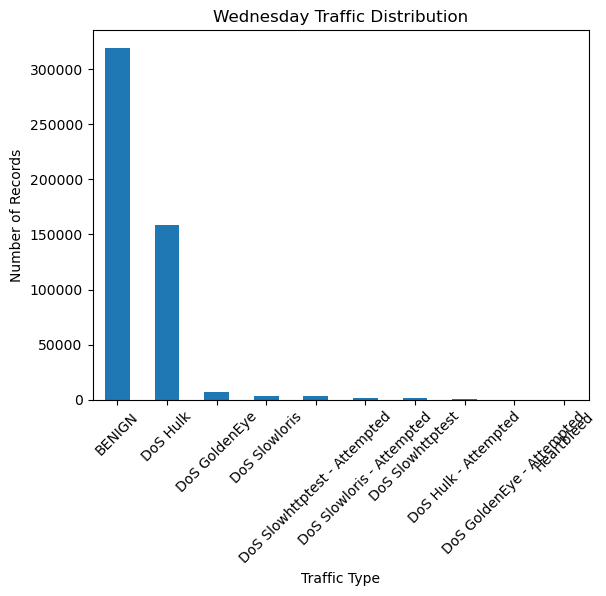

In [92]:
import matplotlib.pyplot as plt

df_wednesday["Label"].value_counts().plot(kind="bar")

plt.title("Wednesday Traffic Distribution")
plt.xlabel("Traffic Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.show()

In [93]:
print("Thursday labels:")
print(df_thursday["Label"].value_counts())

Thursday labels:
Label
BENIGN                                    288171
Infiltration - Portscan                    71767
Web Attack - Brute Force - Attempted        1292
Web Attack - XSS - Attempted                 655
Web Attack - Brute Force                      73
Infiltration - Attempted                      45
Infiltration                                  36
Web Attack - XSS                              18
Web Attack - SQL Injection                    13
Web Attack - SQL Injection - Attempted         5
Name: count, dtype: int64


In [94]:
print(df_thursday["Label"].value_counts())

Label
BENIGN                                    288171
Infiltration - Portscan                    71767
Web Attack - Brute Force - Attempted        1292
Web Attack - XSS - Attempted                 655
Web Attack - Brute Force                      73
Infiltration - Attempted                      45
Infiltration                                  36
Web Attack - XSS                              18
Web Attack - SQL Injection                    13
Web Attack - SQL Injection - Attempted         5
Name: count, dtype: int64


In [95]:
print(df_thursday["Label"].value_counts())

Label
BENIGN                                    288171
Infiltration - Portscan                    71767
Web Attack - Brute Force - Attempted        1292
Web Attack - XSS - Attempted                 655
Web Attack - Brute Force                      73
Infiltration - Attempted                      45
Infiltration                                  36
Web Attack - XSS                              18
Web Attack - SQL Injection                    13
Web Attack - SQL Injection - Attempted         5
Name: count, dtype: int64


In [96]:
print("Dataset Shape:", df_wednesday.shape)

print("\nNumber of Columns:", len(df_wednesday.columns))

print("\nColumn Names:")
print(df_wednesday.columns.tolist())

Dataset Shape: (496640, 89)

Number of Columns: 89

Column Names:
['Src IP dec', 'Src Port', 'Dst IP dec', 'Dst Port', 'Protocol', 'Timestamp', 'Flow Duration', 'Total Fwd Packet', 'Total Bwd packets', 'Total Length of Fwd Packet', 'Total Length of Bwd Packet', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd RST Flags', 'Bwd RST Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Var

In [97]:
print(df_wednesday.dtypes)

Src IP dec              int64
Src Port                int64
Dst IP dec              int64
Dst Port                int64
Protocol                int64
                        ...  
ICMP Code               int64
ICMP Type               int64
Total TCP Flow Time     int64
Label                  object
Attempted Category      int64
Length: 89, dtype: object


In [98]:
missing_values = df_wednesday.isnull().sum()

print(missing_values[missing_values > 0])

Series([], dtype: int64)


In [99]:
print("Duplicate rows:", df_wednesday.duplicated().sum())

Duplicate rows: 6


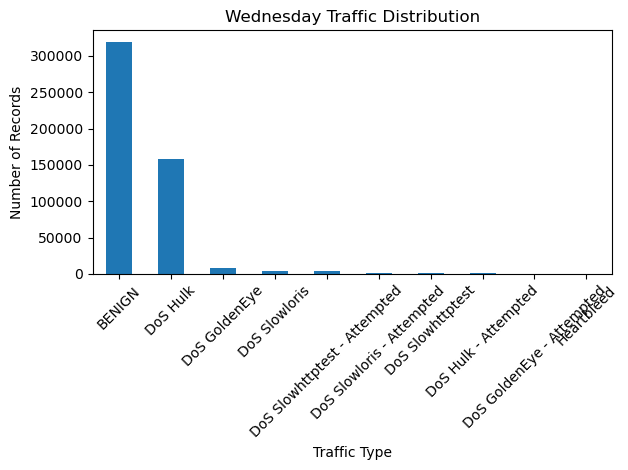

In [100]:
import matplotlib.pyplot as plt

df_wednesday["Label"].value_counts().plot(kind="bar")

plt.title("Wednesday Traffic Distribution")
plt.xlabel("Traffic Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [101]:
label_percentage = df_wednesday["Label"].value_counts(normalize=True) * 100

print(label_percentage)

Label
BENIGN                          64.255598
DoS Hulk                        31.908022
DoS GoldenEye                    1.523639
DoS Slowloris                    0.777022
DoS Slowhttptest - Attempted     0.678157
DoS Slowloris - Attempted        0.371899
DoS Slowhttptest                 0.350354
DoS Hulk - Attempted             0.116986
DoS GoldenEye - Attempted        0.016108
Heartbleed                       0.002215
Name: proportion, dtype: float64


In [102]:
print("Monday:", df.shape)
print("Tuesday:", df_tuesday.shape)
print("Wednesday:", df_wednesday.shape)
print("Thursday:", df_thursday.shape)
print("Friday:", df_friday.shape)

Monday: (371621, 89)
Tuesday: (322078, 89)
Wednesday: (496640, 89)
Thursday: (362075, 89)
Friday: (547557, 89)


In [103]:
print("Total missing values:",
      df_wednesday.isnull().sum().sum())

Total missing values: 0


In [104]:
print("Total duplicate rows:",
      df_wednesday.duplicated().sum())

Total duplicate rows: 6


In [105]:
print(df_wednesday.dtypes)

Src IP dec              int64
Src Port                int64
Dst IP dec              int64
Dst Port                int64
Protocol                int64
                        ...  
ICMP Code               int64
ICMP Type               int64
Total TCP Flow Time     int64
Label                  object
Attempted Category      int64
Length: 89, dtype: object


In [106]:
df_wednesday.describe()

,Src IP dec,Src Port,Dst IP dec,Dst Port,Protocol,Flow Duration,Total Fwd Packet,Total Bwd packets,Total Length of Fwd Packet,Total Length of Bwd Packet,...,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,ICMP Code,ICMP Type,Total TCP Flow Time,Attempted Category
count,4.966400e+05,496640.000000,4.966400e+05,496640.000000,496640.000000,4.966400e+05,496640.000000,496640.000000,496640.000000,4.966400e+05,...,4.966400e+05,4.966400e+05,4.966400e+05,4.966400e+05,4.966400e+05,4.966400e+05,496640.000000,496640.000000,4.966400e+05,496640.000000
mean,3.107179e+09,48202.464469,2.939000e+09,210.367729,10.488809,1.210240e+07,13.214097,14.454698,622.437661,2.381205e+04,...,2.579237e+05,1.018513e+05,4.340820e+06,4.725100e+05,4.805795e+06,3.927907e+06,-0.999847,-0.999742,4.410486e+07,-0.952859
std,1.784051e+08,13889.100033,7.397861e+08,1903.128172,5.412645,3.078214e+07,882.426050,1162.333891,4791.597323,2.646553e+06,...,1.361891e+06,7.916558e+05,1.428775e+07,3.568532e+06,1.539774e+07,1.393295e+07,0.028872,0.040732,4.203993e+08,0.539057
min,1.346109e+08,0.000000,1.885313e+07,0.000000,0.000000,1.000000e+00,0.000000,0.000000,0.000000,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000,-1.000000,0.000000e+00,-1.000000
25%,2.886730e+09,41236.000000,3.232238e+09,53.000000,6.000000,3.048100e+04,2.000000,2.000000,70.000000,1.580000e+02,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000,-1.000000,0.000000e+00,-1.000000
50%,3.232238e+09,52096.000000,3.232238e+09,80.000000,6.000000,1.559870e+05,6.000000,5.000000,308.000000,8.590000e+02,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000,-1.000000,9.804650e+04,-1.000000
75%,3.232238e+09,58614.000000,3.232238e+09,80.000000,17.000000,1.271786e+06,9.000000,7.000000,377.000000,1.159500e+04,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000,-1.000000,1.197753e+06,-1.000000
max,3.559744e+09,65535.000000,4.294967e+09,65178.000000,17.000000,1.200000e+08,203943.000000,272354.000000,819734.000000,6.270464e+08,...,1.049884e+08,1.002421e+08,1.199463e+08,7.691483e+07,1.199463e+08,1.199463e+08,10.000000,8.000000,3.029044e+10,6.000000


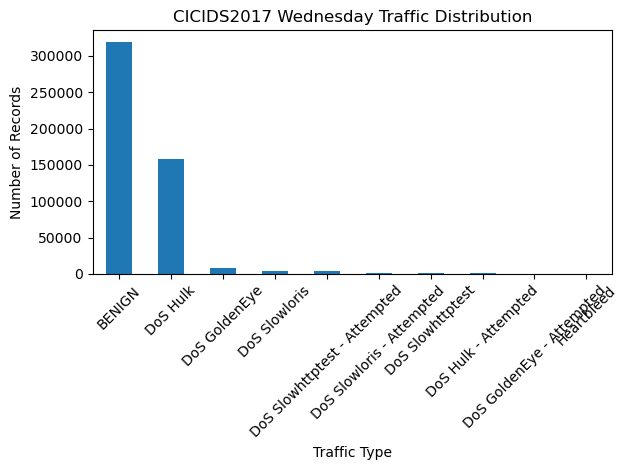

In [107]:
import matplotlib.pyplot as plt

df_wednesday["Label"].value_counts().plot(kind="bar")

plt.title("CICIDS2017 Wednesday Traffic Distribution")
plt.xlabel("Traffic Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [108]:
label_percentage = (
    df_wednesday["Label"]
    .value_counts(normalize=True) * 100
)

print(label_percentage)

Label
BENIGN                          64.255598
DoS Hulk                        31.908022
DoS GoldenEye                    1.523639
DoS Slowloris                    0.777022
DoS Slowhttptest - Attempted     0.678157
DoS Slowloris - Attempted        0.371899
DoS Slowhttptest                 0.350354
DoS Hulk - Attempted             0.116986
DoS GoldenEye - Attempted        0.016108
Heartbleed                       0.002215
Name: proportion, dtype: float64


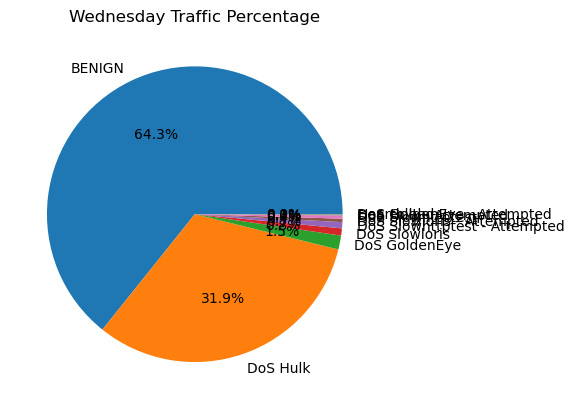

In [109]:
label_percentage.plot(kind="pie", autopct="%1.1f%%")

plt.title("Wednesday Traffic Percentage")
plt.ylabel("")
plt.show()

In [110]:
df_wednesday["Traffic_Type"] = df_wednesday["Label"].apply(
    lambda x: "BENIGN" if x == "BENIGN" else "ATTACK"
)

print(df_wednesday["Traffic_Type"].value_counts())

Traffic_Type
BENIGN    319119
ATTACK    177521
Name: count, dtype: int64


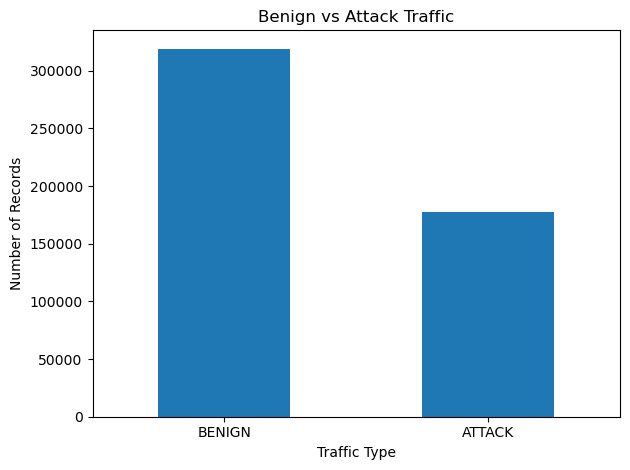

In [111]:
df_wednesday["Traffic_Type"].value_counts().plot(kind="bar")

plt.title("Benign vs Attack Traffic")
plt.xlabel("Traffic Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [112]:
numeric_columns = df_wednesday.select_dtypes(
    include="number"
).columns

print("Number of numerical features:", len(numeric_columns))
print(numeric_columns.tolist())

Number of numerical features: 87
['Src IP dec', 'Src Port', 'Dst IP dec', 'Dst Port', 'Protocol', 'Flow Duration', 'Total Fwd Packet', 'Total Bwd packets', 'Total Length of Fwd Packet', 'Total Length of Bwd Packet', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd RST Flags', 'Bwd RST Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'R

In [113]:
features = [
    "Flow Duration",
    "Total Fwd Packet",
    "Total Bwd packets",
    "Flow Bytes/s",
    "Flow Packets/s"
]

print(df_wednesday[features].describe())

       Flow Duration  Total Fwd Packet  Total Bwd packets  Flow Bytes/s  \
count   4.966400e+05     496640.000000      496640.000000  4.966400e+05   
mean    1.210240e+07         13.214097          14.454698  4.698425e+05   
std     3.078214e+07        882.426050        1162.333891  3.718433e+06   
min     1.000000e+00          0.000000           0.000000  0.000000e+00   
25%     3.048100e+04          2.000000           2.000000  1.406415e+03   
50%     1.559870e+05          6.000000           5.000000  1.197900e+04   
75%     1.271786e+06          9.000000           7.000000  1.424000e+05   
max     1.200000e+08     203943.000000      272354.000000  2.530000e+08   

       Flow Packets/s  
count    4.966400e+05  
mean     5.552094e+03  
std      4.061853e+04  
min      2.500432e-02  
25%      1.024362e+01  
50%      7.500797e+01  
75%      1.999552e+02  
max      2.000000e+06  


In [114]:
print(df_wednesday.columns.tolist())

['Src IP dec', 'Src Port', 'Dst IP dec', 'Dst Port', 'Protocol', 'Timestamp', 'Flow Duration', 'Total Fwd Packet', 'Total Bwd packets', 'Total Length of Fwd Packet', 'Total Length of Bwd Packet', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd RST Flags', 'Bwd RST Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH

## EDA Observations

1. The CICIDS2017 dataset contains network-flow records with 89 columns.
2. The Label column identifies benign and malicious network traffic.
3. The Wednesday dataset contains several DoS attack categories and Heartbleed.
4. The dataset contains both normal and attack traffic.
5. The distribution of traffic classes is imbalanced, with some attack categories having significantly fewer records than BENIGN traffic.
6. This class imbalance should be considered when developing the anomaly-detection model.

In [115]:
print(df.dtypes.value_counts())

int64      62
float64    25
object      2
Name: count, dtype: int64


In [116]:
print(df['Label'].unique())

['BENIGN']


In [117]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 4


# 8. EDA Observations

The analysis of the CICIDS2017 datasets produced the following observations:

- The datasets contain 89 columns representing network-flow features and traffic labels.

- Monday contains 371,621 records, and all records are labeled `BENIGN`.

- Tuesday contains 322,078 records, including 315,106 `BENIGN` records and
  6,972 attack-related records. The attack-related labels include FTP-Patator
  and SSH-Patator categories.

- Wednesday contains 496,640 records, including 319,119 `BENIGN` records and
  177,521 attack-related records. Several DoS categories and Heartbleed are
  present.

- Thursday contains 362,075 records, including 288,171 `BENIGN` records and
  73,904 attack-related records. The dataset includes Infiltration/PortScan
  and several Web Attack categories.

- The traffic labels are highly imbalanced. `BENIGN` is the largest class
  on each of the analyzed days.

- The packet-count analysis shows a wide range of values for
  `Total Fwd Packet` and `Total Bwd packets`, including observations with
  relatively large packet counts.

- The presence of multiple attack categories and class imbalance should be
  considered during preprocessing and model development.

# 9. Conclusion

The exploratory analysis provided an understanding of the structure,
traffic labels, data quality, and network-flow characteristics of the
CICIDS2017 dataset.

The analysis shows that the dataset contains both normal and
attack-related network traffic. Monday contains only benign traffic,
while Tuesday, Wednesday, Thursday, and Friday contain additional
attack-related categories.

Different attack types are present on different days, including
Patator attacks, DoS attacks, Infiltration/PortScan activity, Web Attacks,
and other categories observed in the dataset.

The analysis also shows considerable class imbalance between `BENIGN`
traffic and individual attack categories. Numerical features such as
flow duration and packet counts show substantial variation across
network flows.

These findings provide the basis for the next project stages:
data preprocessing, feature selection, dataset preparation, and
development of network anomaly detection models.